# ArguAna keyword-stuffing attack: Chamfer vs sliced Wasserstein

Evaluates every ranker configuration in `CONFIGS` (as in `search.ipynb`) on the clean ArguAna corpus and on each attacked corpus from `arguana-attack-corpus/` (see its `corpus_modified/README.md`), then makes the `plots.ipynb` figures plus attack-specific ones.

Each attacked dataset `datasets/arguana-attack-<method>/` is the clean corpus plus one adversarial document per query (1,406 per method). Queries, qrels and query vectors are symlinked to `datasets/arguana/`. Only the adversarial documents are encoded. Their vectors are appended to the clean corpus vectors, so the clean rows are identical to those behind the clean runs.

Attack metrics (over judged test queries):
- **ASR@k**: share of queries with an adversarial doc in their top-k. For `targeted`/`topic` only that query's own adversarial doc (`adv-<method>-<query_id>`) counts. `hub` docs target no query, so any hub doc counts.
- **adv@10**: mean number of adversarial docs in the top 10 (any target).
- **Δ nDCG@10**: attacked minus clean nDCG@10 for the same encoder and config (qrels are unchanged, so this is the damage to retrieval quality).

Clean vectors must already exist for each encoder (`python src/encode.py --method <encoder> --datasets arguana`); encoding the adversarial docs needs torch + transformers. Use the **aws** kernel.

In [4]:
%load_ext autoreload
%autoreload 2

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D

from encode import Encoder, encode_split, load_vectors, pick_device
from evaluate import load_qrels
from paths import DATASETS_DIR, RESULTS_DIR, ROOT
from search import find_prefix, run_search

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configure

`CONFIGS` uses the same `(label, ranker, options)` format as `search.ipynb`. `OVERWRITE` re-encodes and re-merges the adversarial vectors (needed if the attack corpus is regenerated).

In [5]:
CLEAN = "arguana"
ATTACK_DIR = ROOT / "arguana-attack-corpus" / "datasets" / CLEAN / "corpus_modified"
ATTACKS = ["targeted", "topic", "hub"]
ENCODERS = ["colbert"]   # add "bert" once datasets/arguana/vec_*/bert exist
K = 100
QRELS_SPLIT = "test"
METRICS = ("ndcg@10", "recall@10", "recall@100", "mrr@10")
ATTACK_KS = (1, 10, 100)
WRITE = True             # save each run to results/<dataset>/<encoder>/ (clean runs overwrite results/arguana/)
OVERWRITE = False
BATCH_SIZE = 64
SAVE = True              # save figures

CONFIGS = [
    ("chamfer",     "chamfer", {}),
    ("chamfer-sym", "chamfer", {"symmetric": True}),
] + [
    (f"sw L={L}",   "sw",      {"slices": L, "quantiles": 32, "p": 2, "seed": 0})
    for L in (16, 32, 64, 128, 256, 512, 1024, 2048)
]

ATTACKED = {a: f"{CLEAN}-attack-{a}" for a in ATTACKS}
DATASETS = [CLEAN, *ATTACKED.values()]
PARQUET = "corpus-00000-of-00001.parquet"

## Build attacked datasets

For each attack and encoder: link the shared pieces, encode the adversarial docs alone into `datasets/arguana-attack-<method>/adversarial/vec_corpus/`, then write clean + adversarial vectors to `vec_corpus/`. The encoder uses the clean vectors' `max_len` so both halves match. Steps that are already done are skipped.

In [6]:
clean_dir = DATASETS_DIR / CLEAN

def link(dst, src):
    """Relative symlink dst -> src (kept if it already exists)."""
    if dst.is_symlink() or dst.exists():
        return
    dst.parent.mkdir(parents=True, exist_ok=True)
    dst.symlink_to(os.path.relpath(src, dst.parent), target_is_directory=src.is_dir())

def read_meta(prefix):
    return json.loads(Path(f"{prefix}.meta.json").read_text())

def merge_vectors(clean, adv, dst, dataset):
    """Write clean vectors followed by adversarial vectors to `dst` (meta last, as in encode.py)."""
    if Path(f"{dst}.meta.json").exists() and not OVERWRITE:
        print(f"  skip {dst.relative_to(ROOT)} (exists)")
        return
    (CV, coff, cids, cmeta), (AV, aoff, aids, ameta) = load_vectors(clean), load_vectors(adv)
    assert cmeta["dim"] == ameta["dim"] and cmeta["max_len"] == ameta["max_len"], (cmeta, ameta)
    assert not set(cids) & set(aids), "adversarial ids collide with clean ids"
    dst.parent.mkdir(parents=True, exist_ok=True)
    V = np.lib.format.open_memmap(f"{dst}.vectors.npy", mode="w+", dtype=CV.dtype,
                                  shape=(len(CV) + len(AV), CV.shape[1]))
    step = 1 << 18
    for s in range(0, len(CV), step):
        e = min(s + step, len(CV))
        V[s:e] = CV[s:e]
    V[len(CV):] = AV
    V.flush()
    del V
    offsets = np.concatenate([coff, aoff[1:] + coff[-1]])
    np.save(f"{dst}.offsets.npy", offsets)
    Path(f"{dst}.ids.json").write_text(json.dumps(cids + aids))
    counts = np.diff(offsets)
    meta = {**cmeta, "dataset": dataset, "num_items": len(counts), "num_vectors": int(offsets[-1]),
            "vectors_per_item": {"min": int(counts.min()), "max": int(counts.max()),
                                 "mean": round(float(counts.mean()), 2)},
            "clean_items": len(cids), "adversarial_items": len(aids)}
    Path(f"{dst}.meta.json").write_text(json.dumps(meta, indent=2))
    print(f"  wrote {dst.relative_to(ROOT)}.*  ({len(cids)} clean + {len(aids)} adversarial)")

for attack, name in ATTACKED.items():
    out, src = DATASETS_DIR / name, ATTACK_DIR / f"attack_corpus_{attack}"
    link(out / "queries", clean_dir / "queries")
    link(out / "qrels", clean_dir / "qrels")
    link(out / "manifest.jsonl", src / "manifest.jsonl")
    link(out / "adversarial" / "corpus" / PARQUET, src / PARQUET)
    if OVERWRITE or not (out / "corpus" / PARQUET).exists():  # merged text, for inspection
        (out / "corpus").mkdir(parents=True, exist_ok=True)
        pd.concat([pd.read_parquet(clean_dir / "corpus"), pd.read_parquet(src / PARQUET)],
                  ignore_index=True).to_parquet(out / "corpus" / PARQUET, index=False)

for method in ENCODERS:
    cq = find_prefix(clean_dir / "vec_queries" / method, None)
    cd = find_prefix(clean_dir / "vec_corpus" / method, None)
    meta = read_meta(cd)
    enc = None
    for attack, name in ATTACKED.items():
        out = DATASETS_DIR / name
        print(f"[{name}] {method}")
        link(out / "vec_queries" / method, cq.parent)
        adv = out / "adversarial" / "vec_corpus" / method / cd.name
        if OVERWRITE or not Path(f"{adv}.meta.json").exists():
            if enc is None:  # load the model only if something needs encoding
                enc = Encoder(method, pick_device("auto"), read_meta(cq)["max_len"], meta["max_len"])
                assert enc.tag("corpus") == cd.name, (enc.tag("corpus"), cd.name)
            encode_split(enc, out / "adversarial", "corpus", BATCH_SIZE, 0, meta["dtype"], OVERWRITE)
        merge_vectors(cd, adv, out / "vec_corpus" / method / cd.name, name)
    del enc

[arguana-attack-targeted] colbert
  skip datasets/arguana-attack-targeted/vec_corpus/colbert/colbertv2.0_d128_nv180 (exists)
[arguana-attack-topic] colbert
  skip datasets/arguana-attack-topic/vec_corpus/colbert/colbertv2.0_d128_nv180 (exists)
[arguana-attack-hub] colbert
  skip datasets/arguana-attack-hub/vec_corpus/colbert/colbertv2.0_d128_nv180 (exists)


## Run

Same loop as `search.ipynb`, over the clean dataset and every attacked one. Rankings are kept in memory for the attack metrics.

In [7]:
rows, rankings = [], {}
for encoder in ENCODERS:
    for dataset in DATASETS:
        for label, ranker, opts in CONFIGS:
            out = run_search(dataset, ranker, encoder, k=K, ignore_identical_ids=True, write=WRITE,
                             qrels_split=QRELS_SPLIT, metrics=METRICS, **opts)
            meta = out["meta"]
            rankings[dataset, encoder, label] = out["results"]
            sw = meta["ranker"] == "sliced_wasserstein"
            rows.append({
                "dataset": dataset, "encoder": encoder, "config": label,
                # same method/slices columns as plots.ipynb
                "method": f"SW K={meta['quantiles']} p={meta['p']}" if sw
                          else ("chamfer-sym" if meta["symmetric"] else "chamfer"),
                "slices": meta["slices"] if sw else np.nan,
                **meta["metrics"], "seconds": meta["seconds"],
            })

[arguana] chamfer: 1406 queries x 8674 docs  device=mps dtype=torch.float16  (loaded in 0.1s)
  8674/8674 docs  (18s)
  ndcg@10=0.4540  recall@10=0.6956  recall@100=0.9075  mrr@10=0.3786
  wrote results/arguana/colbert/chamfer__colbertv2.0_d128_nv32__colbertv2.0_d128_nv180.trec  (19s)
[arguana] chamfer-sym: 1406 queries x 8674 docs  device=mps dtype=torch.float16  (loaded in 0.0s)
  8674/8674 docs  (28s)
  ndcg@10=0.4148  recall@10=0.6643  recall@100=0.8969  mrr@10=0.3377
  wrote results/arguana/colbert/chamfer-sym__colbertv2.0_d128_nv32__colbertv2.0_d128_nv180.trec  (31s)
[arguana] sw_L16_K32_p2_s0: 1406 queries x 8674 docs  device=mps dtype=torch.float16  (loaded in 0.0s)
  8674/8674 docs  (1s)
  ndcg@10=0.0256  recall@10=0.0541  recall@100=0.2091  mrr@10=0.0171
  wrote results/arguana/colbert/sw_L16_K32_p2_s0__colbertv2.0_d128_nv32__colbertv2.0_d128_nv180.trec  (1s)
[arguana] sw_L32_K32_p2_s0: 1406 queries x 8674 docs  device=mps dtype=torch.float16  (loaded in 0.0s)
  8674/8674 doc

## Attack metrics

In [8]:
qrels = load_qrels(CLEAN, QRELS_SPLIT)
manifests = {a: pd.read_json(ATTACK_DIR / f"attack_corpus_{a}" / "manifest.jsonl", lines=True) for a in ATTACKS}

def attack_metrics(results, manifest):
    adv = set(manifest["_id"])
    own = dict(manifest.dropna(subset=["target_query_id"])[["target_query_id", "_id"]].values)
    out = {}
    for k in ATTACK_KS:
        hits = []
        for q in qrels:
            top = [d for d, _ in results.get(q, [])[:k]]
            hits.append(own[q] in top if own else any(d in adv for d in top))
        out[f"asr@{k}"] = float(np.mean(hits))
    out["adv@10"] = float(np.mean([sum(d in adv for d, _ in results.get(q, [])[:10]) for q in qrels]))
    return out

table = pd.DataFrame(rows)
clean = table[table.dataset == CLEAN].set_index(["encoder", "config"])
attack_rows = []
for attack, name in ATTACKED.items():
    for _, r in table[table.dataset == name].iterrows():
        base = clean.loc[(r.encoder, r.config)]
        attack_rows.append({
            "attack": attack, "encoder": r.encoder, "config": r.config, "method": r.method, "slices": r.slices,
            "clean ndcg@10": base["ndcg@10"], "ndcg@10": r["ndcg@10"],
            "Δ ndcg@10": r["ndcg@10"] - base["ndcg@10"],
            **attack_metrics(rankings[name, r.encoder, r.config], manifests[attack]),
        })
attacks = pd.DataFrame(attack_rows)
order = [c[0] for c in CONFIGS]

In [9]:
# Retrieval quality on every dataset: one row per config, one column group per metric and dataset.
table.pivot(index=["encoder", "config"], columns="dataset", values=list(METRICS)) \
     .reindex(order, level="config").reindex(columns=DATASETS, level="dataset")

ndcg@10                                               \
dataset             arguana arguana-attack-targeted arguana-attack-topic   
encoder config                                                             
colbert chamfer      0.4540                  0.3715               0.4304   
        chamfer-sym  0.4148                  0.3884               0.4001   
        sw L=16      0.0256                  0.0253               0.0255   
        sw L=32      0.0905                  0.0890               0.0892   
        sw L=64      0.1610                  0.1566               0.1572   
        sw L=128     0.2202                  0.2147               0.2175   
        sw L=256     0.2578                  0.2517               0.2553   
        sw L=512     0.2741                  0.2664               0.2704   
        sw L=1024    0.2831                  0.2767               0.2798   
        sw L=2048    0.2937                  0.2850               0.2889   

                                       recall@10                          \
dataset             arguana-attack-hub   arguana arguana-attack-targeted   
encoder config                                                             
colbert chamfer                 0.4309    0.6956                  0.6657   
        chamfer-sym             0.4019    0.6643                  0.6550   
        sw L=16                 0.0255    0.0541                  0.0533   
        sw L=32                 0.0902    0.1550                  0.1515   
        sw L=64                 0.1572    0.2902                  0.2831   
        sw L=128                0.2169    0.3634                  0.3549   
        sw L=256                0.2542    0.4267                  0.4175   
        sw L=512                0.2698    0.4609                  0.4459   
        sw L=1024               0.2798    0.4780                  0.4673   
        sw L=2048               0.2885    0.4922                  0.4758   

                                                            recall@100  \
dataset             arguana-attack-topic arguana-attack-hub    arguana   
encoder config                                                           
colbert chamfer                   0.6871             0.6807     0.9075   
        chamfer-sym               0.6600             0.6565     0.8969   
        sw L=16                   0.0541             0.0541     0.2091   
        sw L=32                   0.1522             0.1543     0.4474   
        sw L=64                   0.2838             0.2817     0.6053   
        sw L=128                  0.3570             0.3585     0.6999   
        sw L=256                  0.4225             0.4218     0.7482   
        sw L=512                  0.4566             0.4559     0.7731   
        sw L=1024                 0.4737             0.4730     0.7930   
        sw L=2048                 0.4844             0.4844     0.8087   

                                                                  \
dataset             arguana-attack-targeted arguana-attack-topic   
encoder config                                                     
colbert chamfer                      0.9026               0.9026   
        chamfer-sym                  0.8969               0.8962   
        sw L=16                      0.2041               0.2063   
        sw L=32                      0.4353               0.4339   
        sw L=64                      0.5853               0.5839   
        sw L=128                     0.6863               0.6935   
        sw L=256                     0.7376               0.7440   
        sw L=512                     0.7560               0.7639   
        sw L=1024                    0.7802               0.7866   
        sw L=2048                    0.7895               0.8023   

                                        mrr@10                          \
dataset             arguana-attack-hub arguana arguana-attack-targeted   
encoder config                                

In [10]:
# Attack success: one row per config, one column group per attack metric and attack.
cols = ["Δ ndcg@10", *(f"asr@{k}" for k in ATTACK_KS), "adv@10"]
attacks.pivot(index=["encoder", "config"], columns="attack", values=cols) \
       .reindex(order, level="config").reindex(columns=ATTACKS, level="attack") \
       .style.format("{:+.4f}", subset=["Δ ndcg@10"]).format("{:.3f}", subset=cols[1:])

## Plot: search time vs quality

The `plots.ipynb` figure for each attacked dataset, saved to `results/<dataset>/plots/time_vs_quality.png`. The clean dataset is shown but not saved, so the `plots.ipynb` figure (which may have more encoders) is not overwritten.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


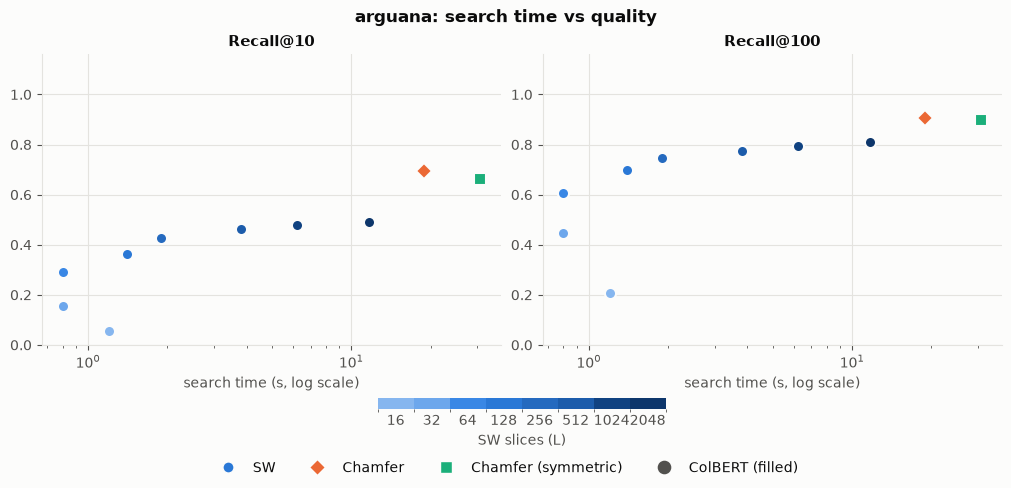

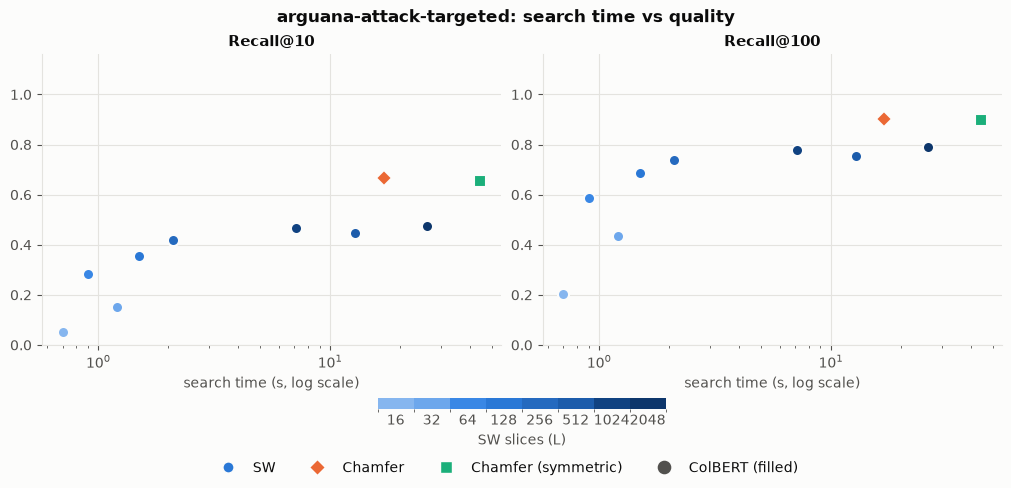

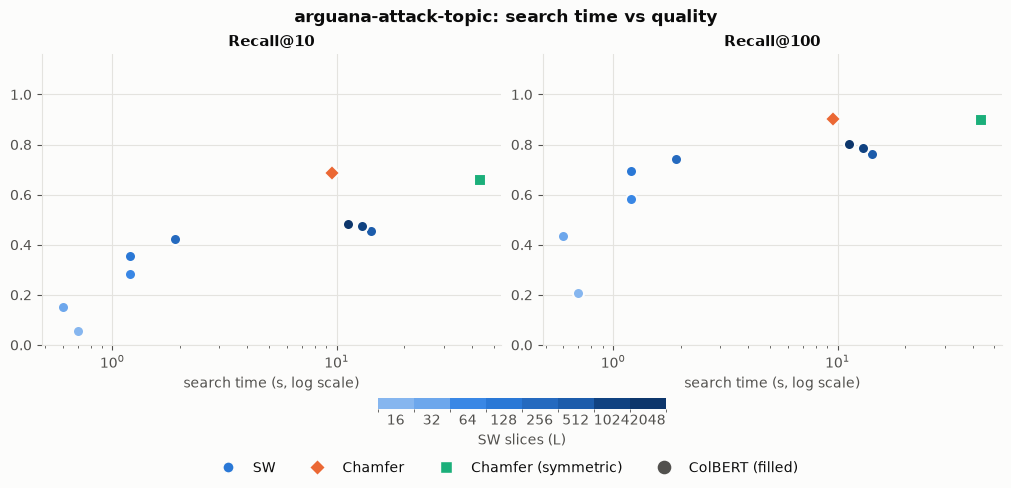

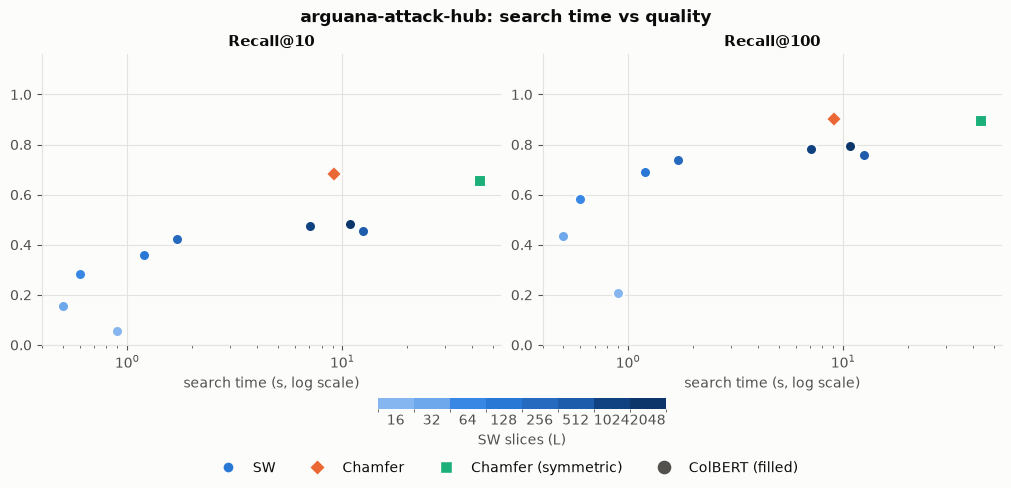

In [11]:
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
# Sequential blue ramp (steps 250 -> 700) for SW slice counts: lighter = fewer slices.
SLICE_RAMP = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
              "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SW_MARKERS = ["o", "^", "v", "P", "X"]   # one shape per SW setting (K, p) if several exist
FIXED = {"chamfer": ("#eb6834", "D", "Chamfer"), "chamfer-sym": ("#1baf7a", "s", "Chamfer (symmetric)")}
ENCODERS_LABEL = {"colbert": "ColBERT (filled)", "bert": "BERT (hollow)"}
METRIC_NAMES = {"ndcg": "nDCG", "recall": "Recall", "mrr": "MRR", "precision": "Precision", "asr": "ASR"}
PLOT_METRICS = ("recall@10", "recall@100")

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold",
})

def slice_colors(slices):
    """Map each distinct slice count to a ramp step, spaced by log2(L)."""
    slices = sorted(slices)
    if len(slices) == 1:
        return {slices[0]: SLICE_RAMP[4]}
    lo, hi = np.log2(slices[0]), np.log2(slices[-1])
    return {L: SLICE_RAMP[round((np.log2(L) - lo) / (hi - lo) * (len(SLICE_RAMP) - 1))] for L in slices}

def draw(ax, x, y, color, marker, filled):
    ax.plot(x, y, ls="none", marker=marker, ms=8, color=color,
            mfc=color if filled else SURFACE, mec=SURFACE if filled else color, mew=1.5 if filled else 1.8)

def slice_colorbar(fig, axes, colors):
    """Slice gradient: one discrete step per slice count."""
    Ls = sorted(colors)
    cmap = ListedColormap([colors[L] for L in Ls])
    norm = BoundaryNorm(np.arange(len(Ls) + 1) - 0.5, len(Ls))
    cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=axes, location="bottom",
                        ticks=range(len(Ls)), shrink=0.3, aspect=25, pad=0.02)
    cbar.ax.set_xticklabels([str(L) for L in Ls])
    cbar.set_label("SW slices (L)", color=INK_2)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, colors=INK_2)

def legend_handles(df, sw_methods):
    """Methods (shape; SW color comes from the gradient) and encoders (fill)."""
    mid = SLICE_RAMP[4]
    handles = [Line2D([], [], ls="none", marker=SW_MARKERS[i % len(SW_MARKERS)], ms=8, color=mid, mec=SURFACE,
                      label="SW" if len(sw_methods) == 1 else m) for i, m in enumerate(sw_methods)]
    handles += [Line2D([], [], ls="none", marker=mk, ms=8, color=c, mec=SURFACE, label=label)
                for m, (c, mk, label) in FIXED.items() if m in set(df.method)]
    handles += [Line2D([], [], ls="none", marker="o", ms=8, color=INK_2, mew=1.8,
                       mfc=SURFACE if e == "bert" else INK_2, mec=INK_2, label=label)
                for e, label in ENCODERS_LABEL.items() if e in set(df.encoder)]
    return handles

def plot_dataset(dataset, df):
    df = df.dropna(subset=["seconds"])
    sw_methods = sorted(m for m in df.method.unique() if m.startswith("SW"))
    colors = slice_colors(df.slices.dropna().astype(int).unique())
    fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(5 * len(PLOT_METRICS), 4.8), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, metric in zip(axes, PLOT_METRICS):
        for _, r in df.iterrows():
            filled = r.encoder != "bert"
            if r.method in FIXED:
                color, marker, _ = FIXED[r.method]
            else:
                color, marker = colors[int(r.slices)], SW_MARKERS[sw_methods.index(r.method) % len(SW_MARKERS)]
            draw(ax, r.seconds, r[metric], color, marker, filled)
        ax.set_xscale("log")
        ax.set_xlabel("search time (s, log scale)")
        kind, k = metric.split("@")
        ax.set_title(f"{METRIC_NAMES.get(kind, kind)}@{k}")
        ax.set_ylim(0, 1.16)
    if colors:
        slice_colorbar(fig, axes, colors)
    handles = legend_handles(df, sw_methods)
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False)
    fig.suptitle(f"{dataset}: search time vs quality", fontweight="semibold", color=INK)
    return fig

runs = table.sort_values(["dataset", "encoder", "method", "slices"], ignore_index=True)
for dataset in DATASETS:
    fig = plot_dataset(dataset, runs[runs.dataset == dataset])
    if SAVE and dataset != CLEAN:
        out = RESULTS_DIR / dataset / "plots"
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / "time_vs_quality.png", dpi=160)
    plt.show()

## Plot: robustness to the attack

One column per attack. SW is a line over slice counts (blue gradient as above). Chamfer and symmetric Chamfer don't depend on slices, so they are horizontal lines. Rows: ASR@10 (lower is more robust), Δ nDCG@10 (closer to 0 is more robust), and attacked nDCG@10 next to its clean value (dotted). Saved to `results/arguana/plots/attack_robustness.png`.

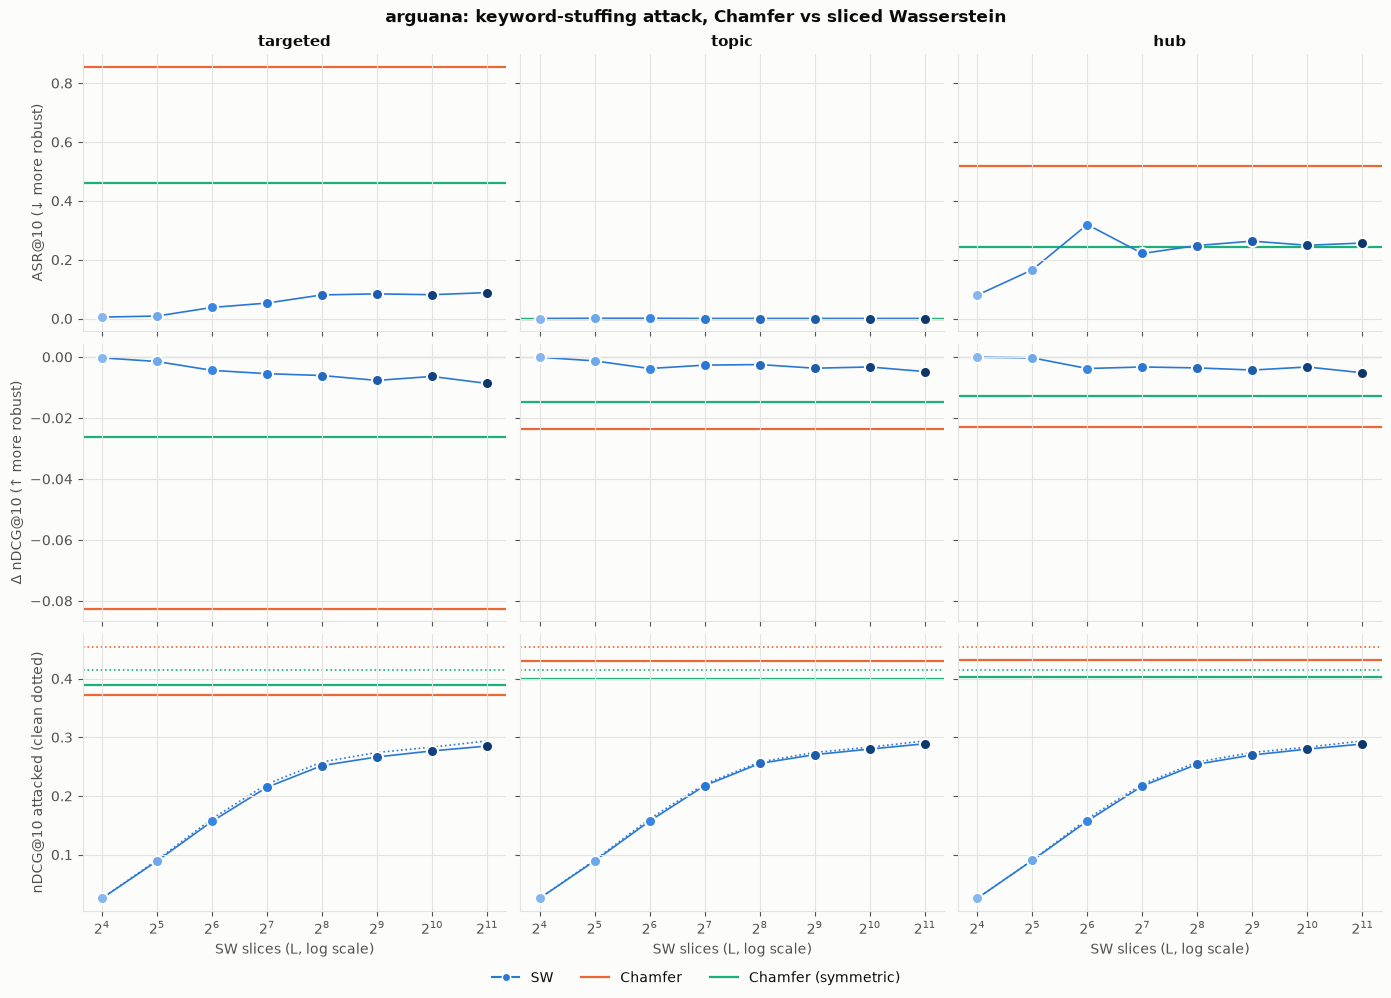

In [12]:
ROBUST_ROWS = [("asr@10", "ASR@10 (↓ more robust)"), ("Δ ndcg@10", "Δ nDCG@10 (↑ more robust)"),
               ("ndcg@10", "nDCG@10 attacked (clean dotted)")]
ENC_STYLE = {"colbert": "-", "bert": "--"}

def plot_robustness(df):
    colors = slice_colors(df.slices.dropna().astype(int).unique())
    fig, axes = plt.subplots(len(ROBUST_ROWS), len(ATTACKS), figsize=(4.6 * len(ATTACKS), 3.3 * len(ROBUST_ROWS)),
                             sharex=True, sharey="row", constrained_layout=True, squeeze=False)
    for j, attack in enumerate(ATTACKS):
        for i, (metric, ylabel) in enumerate(ROBUST_ROWS):
            ax = axes[i, j]
            for encoder, d in df[df.attack == attack].groupby("encoder"):
                filled, ls = encoder != "bert", ENC_STYLE.get(encoder, "-")
                sw = d[d.method.str.startswith("SW")].sort_values("slices")
                ax.plot(sw.slices, sw[metric], ls=ls, color=SLICE_RAMP[4], lw=1.2, zorder=1)
                for _, r in sw.iterrows():
                    draw(ax, r.slices, r[metric], colors[int(r.slices)], SW_MARKERS[0], filled)
                for m, (c, _, _) in FIXED.items():
                    v = d.loc[d.method == m, metric]
                    if len(v):
                        ax.axhline(v.iloc[0], color=c, ls=ls, lw=1.6, zorder=0)
                if metric == "ndcg@10":
                    ax.plot(sw.slices, sw["clean ndcg@10"], ls=":", color=SLICE_RAMP[4], lw=1.2, zorder=1)
                    for m, (c, _, _) in FIXED.items():
                        v = d.loc[d.method == m, "clean ndcg@10"]
                        if len(v):
                            ax.axhline(v.iloc[0], color=c, ls=":", lw=1.2, zorder=0)
            if metric == "Δ ndcg@10":
                ax.axhline(0, color=INK_2, lw=0.8, zorder=0)
            ax.set_xscale("log", base=2)
            if i == 0:
                ax.set_title(attack)
            if j == 0:
                ax.set_ylabel(ylabel)
            if i == len(ROBUST_ROWS) - 1:
                ax.set_xlabel("SW slices (L, log scale)")
    handles = [Line2D([], [], color=SLICE_RAMP[4], marker=SW_MARKERS[0], mec=SURFACE, label="SW")]
    handles += [Line2D([], [], color=c, lw=1.6, label=label) for m, (c, _, label) in FIXED.items()
                if m in set(df.method)]
    handles += [Line2D([], [], color=INK_2, ls=ENC_STYLE.get(e, "-"), label=ENCODERS_LABEL[e].split(" (")[0])
                for e in ENCODERS if len(ENCODERS) > 1]
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False)
    fig.suptitle(f"{CLEAN}: keyword-stuffing attack, Chamfer vs sliced Wasserstein",
                 fontweight="semibold", color=INK)
    return fig

fig = plot_robustness(attacks)
if SAVE:
    out = RESULTS_DIR / CLEAN / "plots"
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "attack_robustness.png", dpi=160)
plt.show()

## Table

The attack numbers, one row per attack, encoder and config.

In [13]:
attacks.drop(columns="method").style.format(
    {"slices": "{:.0f}", "clean ndcg@10": "{:.4f}", "ndcg@10": "{:.4f}", "Δ ndcg@10": "{:+.4f}", "adv@10": "{:.2f}"}
    | {f"asr@{k}": "{:.3f}" for k in ATTACK_KS}, na_rep="–").hide(axis="index")

attack,encoder,config,slices,clean ndcg@10,ndcg@10,Δ ndcg@10,asr@1,asr@10,asr@100,adv@10
targeted,colbert,chamfer,–,0.4540,0.3715,-0.0825,0.356,0.855,0.986,1.72
targeted,colbert,chamfer-sym,–,0.4148,0.3884,-0.0264,0.087,0.462,0.886,0.79
targeted,colbert,sw L=16,16,0.0256,0.0253,-0.0003,0.001,0.005,0.030,0.23
targeted,colbert,sw L=32,32,0.0905,0.0890,-0.0015,0.001,0.009,0.100,0.27
targeted,colbert,sw L=64,64,0.1610,0.1566,-0.0044,0.004,0.038,0.253,0.57
targeted,colbert,sw L=128,128,0.2202,0.2147,-0.0055,0.005,0.053,0.306,0.52
targeted,colbert,sw L=256,256,0.2578,0.2517,-0.0061,0.009,0.080,0.388,0.55
targeted,colbert,sw L=512,512,0.2741,0.2664,-0.0077,0.012,0.084,0.434,0.57
targeted,colbert,sw L=1024,1024,0.2831,0.2767,-0.0064,0.008,0.081,0.426,0.49
targeted,colbert,sw L=2048,2048,0.2937,0.2850,-0.0087,0.011,0.088,0.456,0.52


In [ ]:
# attacks.to_csv(RESULTS_DIR / CLEAN / "attack.csv", index=False)